| **Inicio**         | **atrás 1**                          | **Siguiente 3**                                    |
| ------------------ | ------------------------------------ | -------------------------------------------------- |
| [🏠](../README.md) | [⏪](./6_1_Errores.ipynb) | [⏩](./6_3_Interpolacion.ipynb) |

# 1. ¿Qué significa encontrar una raíz?

Considera:

$f(x)=x^2-4$.

Queremos:

$x^2-4=0$.

Analíticamente:

$x=\pm2$.

Geométricamente, las raíces son los lugares donde la función cruza:

$y=0$.

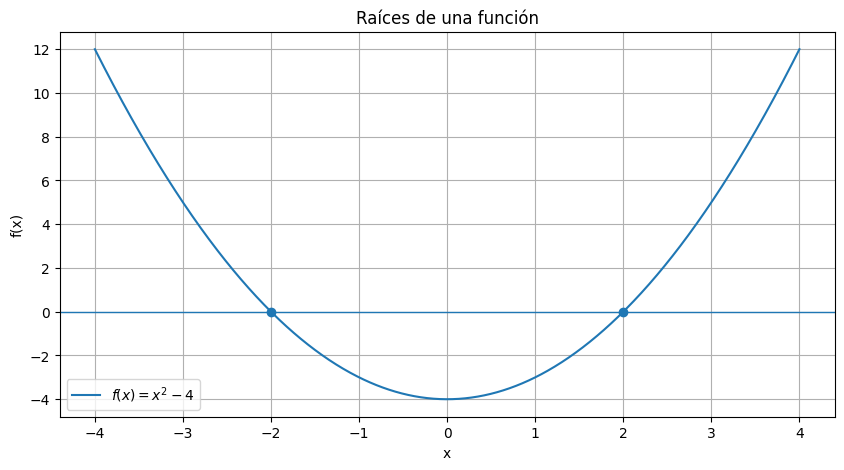

In [1]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-4, 4, 1000)

f = x**2 - 4

plt.figure(figsize=(10, 5))

plt.plot(x, f, label=r"$f(x)=x^2-4$")
plt.axhline(0, linewidth=1)

plt.scatter([-2, 2], [0, 0], zorder=3)

plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Raíces de una función")
plt.legend()
plt.grid()

plt.show()

Tenemos:

$f(-2)=0,\qquad f(2)=0$.

Hasta aquí parece trivial.

El problema interesante aparece cuando tenemos ecuaciones como:

$x=e^{-x}$

o:

$x^3-2x-5=0$

o incluso:

$x\cos x-\sin x=0$.

No siempre existe una fórmula práctica para despejar $(x)$.

Ahí necesitamos métodos numéricos.

# 2. Root finding aparece constantemente en ciencia

Un problema científico muchas veces tiene forma:

$F(x)=b$.

Podemos convertirlo en:

$F(x)-b=0$.

Por ejemplo, si queremos determinar cuándo una temperatura alcanza $(50^\circ C)$:

$T(t)=50$,

definimos:

$f(t)=T(t)-50$

y resolvemos:

$f(t)=0$.

La raíz ahora representa **el tiempo en que ocurre el evento**.

Esto aparece en:

- ODEs;
- detección de eventos;
- equilibrio químico;
- mecánica;
- circuitos;
- transferencia de calor;
- fluidos;
- astronomía;
- optimización;
- estimación de parámetros;
- SciML.

# 3. Los tres métodos que estudiarás

Vamos a comparar:

$\boxed{\text{Bisección}}$

usa un **intervalo**:

$[a,b]$.

$\boxed{\text{Newton-Raphson}}$

usa un punto:

$x_0$

y la derivada:

$f'(x)$.


$\boxed{\text{Secante}}$

usa dos puntos:

$x_0,x_1$

pero **no necesita derivada**.

Una comparación inicial:

| Método | Necesita derivada | Puntos iniciales | Velocidad típica | Robustez |
|---|---:|---:|---:|---:|
| Bisección | No | intervalo | lenta | muy alta |
| Newton | Sí | 1 | muy rápida | menor |
| Secante | No | 2 | rápida | intermedia |

Pero esto es sólo el comienzo.

# 4. Método de Bisección

La bisección explota una propiedad muy sencilla.

Si $(f)$ es continua y:

$f(a)f(b)<0$,

entonces $f(a)$ y $f(b)$ tienen signos diferentes.

Por ejemplo:

$f(a)<0$

y

$f(b)>0$.

Por el teorema del valor intermedio existe al menos una raíz:

$x^*\in(a,b)$.

# 5. Ejemplo

Consideremos:

$f(x)=x^3-x-2$.

Probemos:

$f(1)=1-1-2=-2$

y:

$f(2)=8-2-2=4$.

Tenemos:

$f(1)f(2)<0$.

Por tanto existe una raíz en:

$[1,2]$.

Visualicemos.

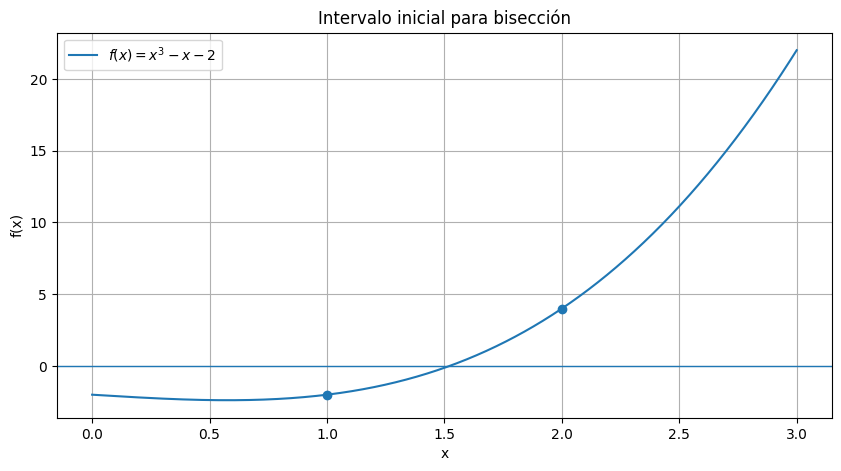

In [2]:
import numpy as np
import matplotlib.pyplot as plt

def f(x):
    return x**3 - x - 2

x = np.linspace(0, 3, 1000)

plt.figure(figsize=(10, 5))

plt.plot(x, f(x), label=r"$f(x)=x^3-x-2$")
plt.axhline(0, linewidth=1)

plt.scatter(
    [1, 2],
    [f(1), f(2)],
    zorder=3
)

plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Intervalo inicial para bisección")
plt.legend()
plt.grid()

plt.show()

# 6. ¿Cómo funciona Bisección?

Tenemos:

$[a,b]=[1,2]$.

Calculamos el punto medio:

$c=\frac{a+b}{2}$.

Entonces:

$c=1.5$.

Evaluamos:

$f(1.5)
=$
$1.5^3-1.5-2
=$
$-0.125$.

Tenemos ahora:

$f(1.5)<0$

y:

$f(2)>0$.

La raíz debe estar en:

$[1.5,2]$.

Volvemos a dividir:

$c=\frac{1.5+2}{2}=1.75$.

Y repetimos.

Conceptualmente:

$[1,2]$

$\downarrow$

$[1.5,2]$

$\downarrow$

$[1.5,1.75]$

$\downarrow$

$\cdots$

Cada iteración reduce el intervalo a la mitad.

# 7. Implementemos Bisección desde cero

In [3]:
import numpy as np

def bisection(f, a, b, tol=1e-10, max_iter=100):

    if f(a) * f(b) > 0:
        raise ValueError(
            "f(a) y f(b) deben tener signos opuestos."
        )

    history = []

    for iteration in range(max_iter):

        c = (a + b) / 2

        history.append(c)

        if abs(f(c)) < tol or (b - a) / 2 < tol:
            return c, history

        if f(a) * f(c) < 0:
            b = c
        else:
            a = c

    return c, history


def f(x):
    return x**3 - x - 2


root, history = bisection(
    f,
    1,
    2
)

print("Raíz =", root)
print("f(raíz) =", f(root))
print("Iteraciones =", len(history))

Raíz = 1.5213797067990527
f(raíz) = -3.277955684666267e-11
Iteraciones = 33



Obtendremos aproximadamente:

$\boxed{x^*\approx1.5213797068}$

# 8. Visualizar las iteraciones de Bisección

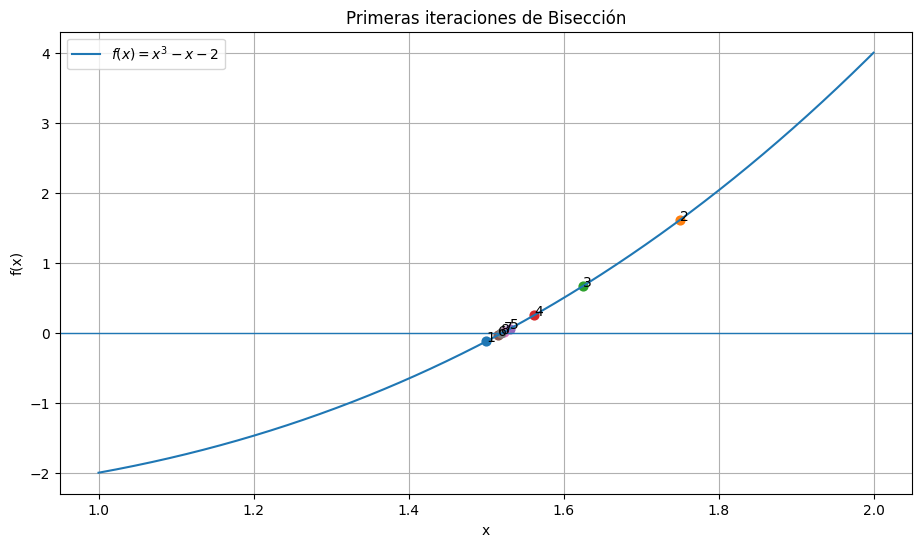

In [4]:
x = np.linspace(1, 2, 1000)

plt.figure(figsize=(11, 6))

plt.plot(
    x,
    f(x),
    label=r"$f(x)=x^3-x-2$"
)

plt.axhline(0, linewidth=1)

for i, c in enumerate(history[:8]):

    plt.scatter(
        c,
        f(c),
        s=40
    )

    plt.annotate(
        str(i + 1),
        (c, f(c))
    )

plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Primeras iteraciones de Bisección")
plt.legend()
plt.grid()

plt.show()

Los puntos se van acercando a:

$x^*\approx1.52138$.

# 9. Error de Bisección

Aquí aparece una ventaja enorme.

Sabemos exactamente cómo disminuye el intervalo.

Inicialmente:

$L_0=b-a$.

Después de una iteración:

$L_1=\frac{b-a}{2}$.

Después de $(n)$:

$L_n=\frac{b-a}{2^n}$

Por tanto podemos garantizar un error del orden de:

$
\boxed{
|x_n-x^*|
\le
\frac{b-a}{2^n}
}
$

dependiendo de la convención usada para el iterado.

Si queremos:

$\frac{b-a}{2^n}<\epsilon$,

entonces:

$n>
\log_2
\left(
\frac{b-a}{\epsilon}
\right)$.

Esto significa que **antes de ejecutar el algoritmo podemos estimar cuántas iteraciones necesitamos**.

# 10. Convergencia de Bisección

Bisección tiene **convergencia lineal**.

A grandes rasgos:

$e_{n+1}\approx C e_n$.

En este caso el intervalo se reduce por un factor:

$\frac12$.

Es robusto, pero no especialmente rápido.

Visualicemos el error.

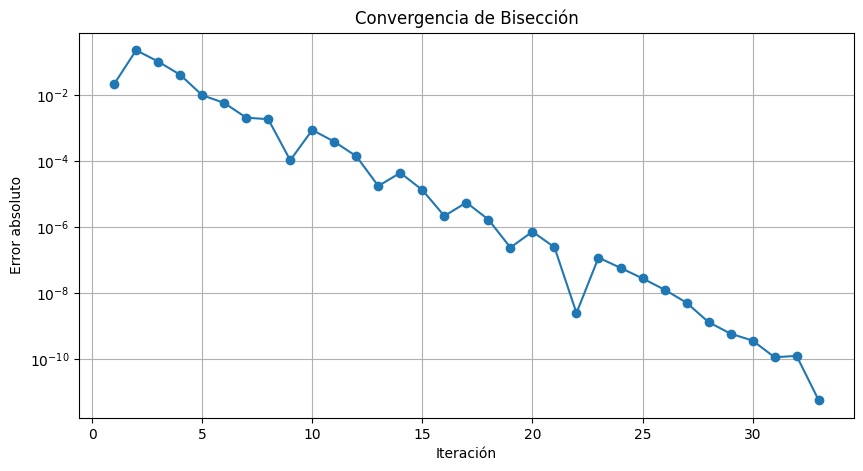

In [5]:
true_root = 1.5213797068045676

errors_bisection = np.abs(
    np.array(history) - true_root
)

plt.figure(figsize=(10, 5))

plt.semilogy(
    range(1, len(errors_bisection) + 1),
    errors_bisection,
    marker="o"
)

plt.xlabel("Iteración")
plt.ylabel("Error absoluto")
plt.title("Convergencia de Bisección")
plt.grid()

plt.show()

# 11. Newton-Raphson

Ahora damos un salto importante.

Newton utiliza la **derivada**.

Supongamos que estamos en:

$x_n$.

Construimos la recta tangente a $f(x)$:

$y
=$
$f(x_n)
+$
$f'(x_n)(x-x_n)$.

Queremos saber dónde esa recta cruza:

$y=0$.

Entonces:


$0
=$
$f(x_n)
+$
$f'(x_n)(x_{n+1}-x_n)$.

Despejamos:

$f'(x_n)(x_{n+1}-x_n)
=$
$-f(x_n)$

y finalmente:

$x_{n+1}
=$
$x_n
-$
$\frac{f(x_n)}
{f'(x_n)}
$

Ésta es la fórmula de Newton-Raphson.

# 12. Intuición geométrica

Tenemos una curva.

Elegimos:

$x_0$.

Calculamos su tangente.

La intersección de la tangente con el eje $(x)$ nos da:

$x_1$.

Después repetimos:

$x_1\rightarrow x_2\rightarrow x_3\rightarrow\cdots$

hasta llegar a la raíz.

# 13. Newton para nuestro problema

Tenemos:

$f(x)=x^3-x-2$.

Su derivada:

$f'(x)=3x^2-1$.

Newton:

$x_{n+1}
=$
$x_n
-$
$\frac{x_n^3-x_n-2}
{3x_n^2-1}$

Implementemos.

In [6]:
import numpy as np

def f(x):
    return x**3 - x - 2

def df(x):
    return 3*x**2 - 1


def newton(f, df, x0, tol=1e-12, max_iter=100):

    x = x0

    history = [x]

    for iteration in range(max_iter):

        derivative = df(x)

        if abs(derivative) < 1e-14:
            raise ValueError(
                "Derivada demasiado cercana a cero."
            )

        x_new = (
            x
            - f(x) / derivative
        )

        history.append(x_new)

        if abs(x_new - x) < tol:
            return x_new, history

        x = x_new

    return x, history


root_newton, history_newton = newton(
    f,
    df,
    x0=2
)

print("Raíz =", root_newton)
print("f(raíz) =", f(root_newton))
print("Iteraciones =", len(history_newton) - 1)

Raíz = 1.5213797068045676
f(raíz) = 0.0
Iteraciones = 6


Normalmente Newton necesita muchas menos iteraciones que Bisección.

# 14. Visualización geométrica de Newton

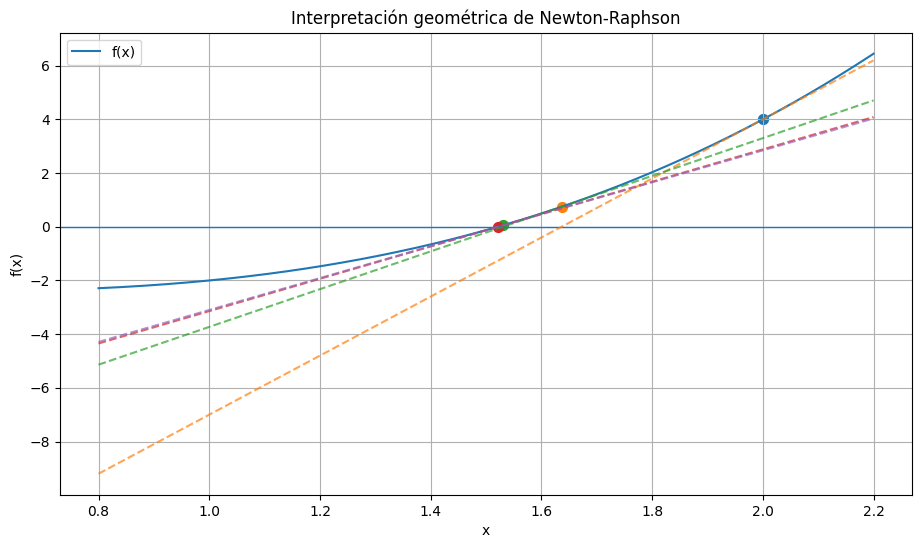

In [7]:
x_plot = np.linspace(
    0.8,
    2.2,
    1000
)

plt.figure(figsize=(11, 6))

plt.plot(
    x_plot,
    f(x_plot),
    label="f(x)"
)

plt.axhline(0, linewidth=1)

x_n = 2.0

for i in range(4):

    y_n = f(x_n)

    slope = df(x_n)

    tangent = (
        y_n
        + slope * (x_plot - x_n)
    )

    plt.plot(
        x_plot,
        tangent,
        linestyle="--",
        alpha=0.7
    )

    plt.scatter(
        x_n,
        y_n,
        s=50
    )

    x_n = (
        x_n
        - f(x_n) / df(x_n)
    )

plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Interpretación geométrica de Newton-Raphson")

plt.legend()
plt.grid()

plt.show()

Observa que cada tangente produce una nueva aproximación.

# 15. ¿Por qué Newton es tan rápido?

Cerca de una raíz simple $(x^*)$, Newton suele tener:

$\boxed{\text{convergencia cuadrática}}$

Esto significa aproximadamente:

$\boxed{
e_{n+1}
\approx
C e_n^2
}$

donde:

$e_n=|x_n-x^*|$.

Supongamos aproximadamente:

$e_n=10^{-2}$.

Entonces podría ocurrir:

$e_{n+1}\sim10^{-4}$

y después:

$e_{n+2}\sim10^{-8}$

y:

$e_{n+3}\sim10^{-16}$.

Por eso Newton puede ganar aproximadamente muchos dígitos correctos en pocas iteraciones cuando ya está cerca de la raíz.

# 16. Visualicemos la convergencia cuadrática

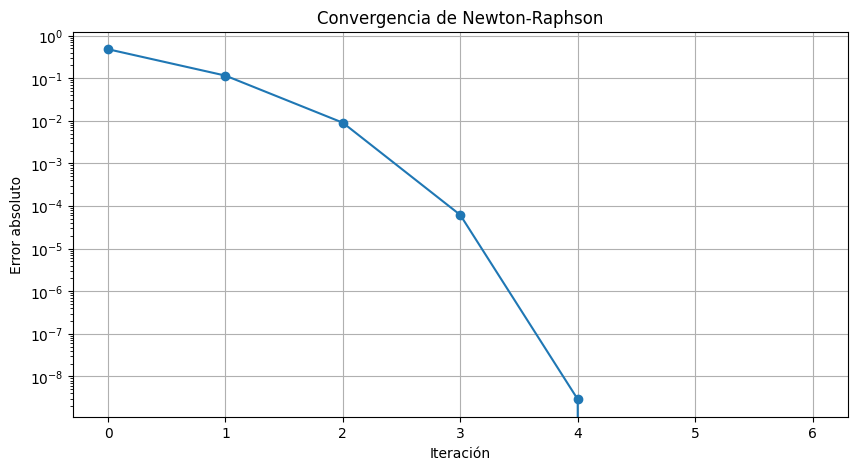

In [8]:
errors_newton = np.abs(
    np.array(history_newton)
    - true_root
)

plt.figure(figsize=(10, 5))

plt.semilogy(
    range(len(errors_newton)),
    errors_newton,
    marker="o"
)

plt.xlabel("Iteración")
plt.ylabel("Error absoluto")
plt.title("Convergencia de Newton-Raphson")
plt.grid()

plt.show()

Compárala mentalmente con Bisección.

Newton suele caer muchísimo más rápido.

# 17. Pero Newton puede fallar

Aquí está la gran diferencia.

Bisección es lenta pero extremadamente robusta.

Newton es rápido pero puede tener problemas.

## Problema 1: derivada cercana a cero

La fórmula contiene:

$\frac{1}{f'(x_n)}$.

Si:

$f'(x_n)\approx0$,

entonces:

$\frac{f(x_n)}{f'(x_n)}$

puede hacerse enorme.

Newton puede saltar a una región completamente diferente.

# 18. Ejemplo difícil donde Newton se comporta mal

Considera:

$f(x)=x^3-2x+2$.

Entonces:

$f'(x)=3x^2-2$.

Empezamos con:

$x_0=0$.

Newton produce:

$x_1
=$
$0-\frac{2}{-2}
=$
$1$.

Ahora:

$f(1)=1$.

$f'(1)=1$.

Entonces:

$x_2=1-\frac11=0$.

¡Volvemos a cero!

Por tanto:

$\boxed{
0\rightarrow1\rightarrow0\rightarrow1\rightarrow\cdots
}$

Newton entra en un ciclo.

Compruébalo:

In [9]:
def f_bad(x):
    return x**3 - 2*x + 2

def df_bad(x):
    return 3*x**2 - 2


x = 0.0

values = [x]

for _ in range(15):

    x = (
        x
        - f_bad(x) / df_bad(x)
    )

    values.append(x)

print(values)

[0.0, 1.0, 0.0, 1.0, 0.0, 1.0, 0.0, 1.0, 0.0, 1.0, 0.0, 1.0, 0.0, 1.0, 0.0, 1.0]


Esto es una demostración excelente de que:

$\boxed{
\text{Newton rápido}
\neq
\text{Newton siempre convergente}
}$

Newton se vuelve todavía más interesante si una función tiene múltiples raíces.

Dependiendo de:

$x_0$,

puedes converger a diferentes raíces.

En problemas complejos incluso aparecen estructuras fractales conocidas como **Newton fractals**.

Esto tiene una conexión profunda con sistemas dinámicos:

$x_{n+1}
=$
$G(x_n)$

donde:

$G(x)
=$
$x-\frac{f(x)}{f'(x)}$.

Es decir, Newton mismo puede verse como un **sistema dinámico discreto**.

# 20. Método de la Secante

Newton necesita:

$f'(x)$.

¿Y si la derivada es:

- difícil;
- cara;
- desconocida;
- imposible de obtener analíticamente?

Podemos aproximarla mediante:

$f'(x_n)
\approx
\frac{
f(x_n)-f(x_{n-1})
}{
x_n-x_{n-1}
}$.

Introducimos esto en Newton:

$x_{n+1}
=$
$x_n
-$
$\frac{f(x_n)}
{
\dfrac{
f(x_n)-f(x_{n-1})
}{
x_n-x_{n-1}
}
}$.

Simplificando:

$x_{n+1}
=$
$x_n
-$
$f(x_n)
\frac{
x_n-x_{n-1}
}{
f(x_n)-f(x_{n-1})
}$

Éste es el **método de la Secante**.

# 21. Diferencia geométrica Newton vs Secante

Newton construye una:

$\boxed{\text{tangente}}$

utilizando:

$f'(x_n)$.

Secante construye una línea que pasa por:

$(x_{n-1},f(x_{n-1}))$

y:

$(x_n,f(x_n))$.

Por eso se llama **secante**.

No necesitamos conocer la derivada.

# 22. Implementación desde cero

In [10]:
def secant(
    f,
    x0,
    x1,
    tol=1e-12,
    max_iter=100
):

    history = [x0, x1]

    for iteration in range(max_iter):

        f0 = f(x0)
        f1 = f(x1)

        denominator = f1 - f0

        if abs(denominator) < 1e-14:
            raise ValueError(
                "Denominador demasiado cercano a cero."
            )

        x2 = (
            x1
            - f1
            * (x1 - x0)
            / denominator
        )

        history.append(x2)

        if abs(x2 - x1) < tol:
            return x2, history

        x0 = x1
        x1 = x2

    return x2, history


root_secant, history_secant = secant(
    f,
    1,
    2
)

print("Raíz =", root_secant)
print("f(raíz) =", f(root_secant))
print("Iteraciones =", len(history_secant) - 2)

Raíz = 1.5213797068045676
f(raíz) = 0.0
Iteraciones = 8


De nuevo obtenemos aproximadamente:

$x^*=1.5213797068$.

# 23. Visualización de Secante

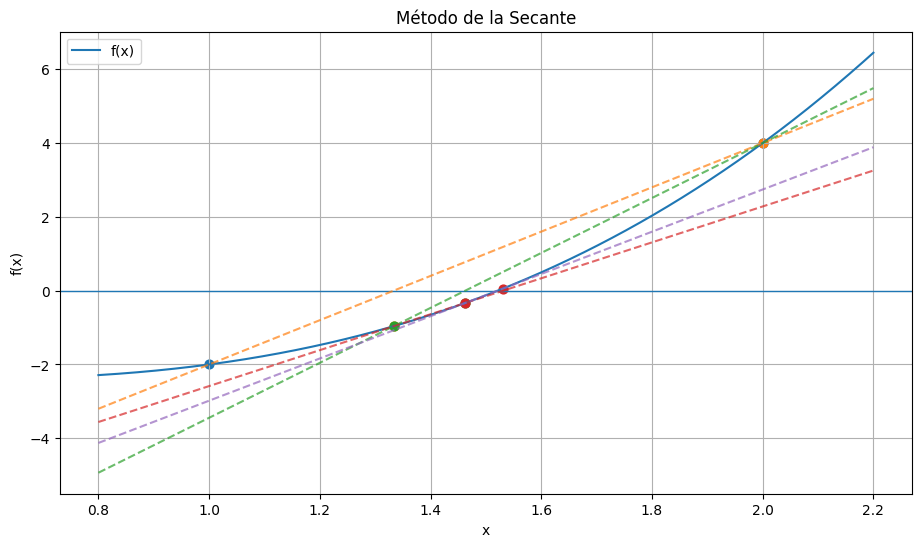

In [11]:
x_plot = np.linspace(
    0.8,
    2.2,
    1000
)

plt.figure(figsize=(11, 6))

plt.plot(
    x_plot,
    f(x_plot),
    label="f(x)"
)

plt.axhline(0, linewidth=1)

x0 = 1.0
x1 = 2.0

for i in range(4):

    f0 = f(x0)
    f1 = f(x1)

    slope = (
        (f1 - f0)
        / (x1 - x0)
    )

    secant_line = (
        f1
        + slope
        * (x_plot - x1)
    )

    plt.plot(
        x_plot,
        secant_line,
        linestyle="--",
        alpha=0.7
    )

    plt.scatter(
        [x0, x1],
        [f0, f1],
        s=40
    )

    x2 = (
        x1
        - f1
        * (x1 - x0)
        / (f1 - f0)
    )

    x0 = x1
    x1 = x2

plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Método de la Secante")

plt.legend()
plt.grid()

plt.show()

# 24. Velocidad de convergencia de Secante

Bisección:

$p=1$.

Newton:

$p=2$.

Secante tiene aproximadamente:

$p=
\frac{1+\sqrt5}{2}$

es decir:

$\boxed{
p\approx1.618
}$

¡Aparece la proporción áurea!

Por tanto:

$1<1.618<2$.

Secante suele ser:

$\boxed{
\text{más rápida que Bisección}
}$

pero:

$\boxed{
\text{más lenta que Newton}
}$

cerca de una raíz simple bajo condiciones favorables.

Pero evita calcular $(f')$.

# 25. Comparación experimental de los tres

Hagámoslo correctamente usando:

$f(x)=x^3-x-2$.

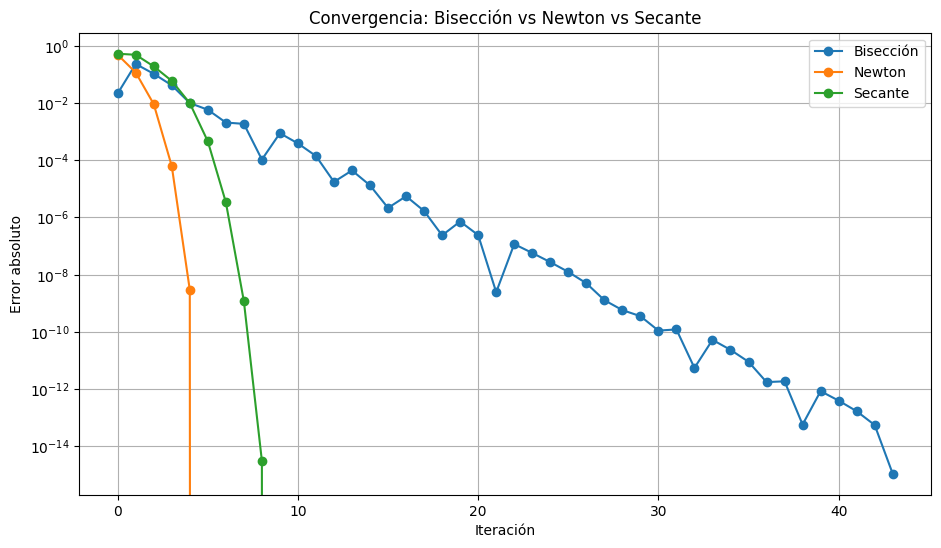

In [12]:
import numpy as np
import matplotlib.pyplot as plt

true_root = 1.5213797068045676

# Bisección
root_bis, hist_bis = bisection(
    f,
    1,
    2,
    tol=1e-14
)

# Newton
root_new, hist_new = newton(
    f,
    df,
    2,
    tol=1e-14
)

# Secante
root_sec, hist_sec = secant(
    f,
    1,
    2,
    tol=1e-14
)

error_bis = np.abs(
    np.array(hist_bis)
    - true_root
)

error_new = np.abs(
    np.array(hist_new)
    - true_root
)

error_sec = np.abs(
    np.array(hist_sec)
    - true_root
)

plt.figure(figsize=(11, 6))

plt.semilogy(
    np.arange(len(error_bis)),
    error_bis,
    marker="o",
    label="Bisección"
)

plt.semilogy(
    np.arange(len(error_new)),
    error_new,
    marker="o",
    label="Newton"
)

plt.semilogy(
    np.arange(len(error_sec)),
    error_sec,
    marker="o",
    label="Secante"
)

plt.xlabel("Iteración")
plt.ylabel("Error absoluto")

plt.title(
    "Convergencia: Bisección vs Newton vs Secante"
)

plt.legend()
plt.grid()

plt.show()

Deberías observar que Newton cae muy rápidamente.

# 26. Cuidado con $abs(f(x))$

Aquí hay una conexión importante con tu tema anterior de **errores y conditioning**.

Es tentador decir:

$|f(x)|\ll1$

entonces:

$x$

debe estar muy cerca de la raíz.

No necesariamente.

Cerca de una raíz $(x^*)$:

$f(x)
\approx
f(x^*)
+
f'(x^*)(x-x^*)$.

Como:

$f(x^*)=0$,

tenemos:

$f(x)
\approx
f'(x^*)(x-x^*)$.

Entonces:

$\boxed{
x-x^*
\approx
\frac{f(x)}
{f'(x^*)}
}$

Si:

$|f'(x^*)|$

es muy pequeño, un residual pequeño puede corresponder a un error considerable en $(x)$.

Esto conecta **root finding con conditioning**.

# 27. Conditioning de una raíz

Supongamos:

$f(x,\alpha)=0$

La raíz depende de algún parámetro:

$x^*=x^*(\alpha)$

Diferenciamos implícitamente:

$f_x
\frac{dx^*}{d\alpha}
+$
$f_\alpha
=$
$0$

Entonces:

$
\frac{dx^*}{d\alpha}
=$
$-
\frac{f_\alpha}{f_x}
$

Si:

$f_x\approx0$,

la raíz puede ser extremadamente sensible.

Otra vez aparece:

$\frac1{f_x}$

Eso explica matemáticamente por qué raíces donde la función es casi horizontal pueden ser difíciles.

# 28. Raíces múltiples y Newton

Consideremos:

$f(x)=(x-1)^2$

La raíz:

$x^*=1$

tiene multiplicidad 2.

La derivada:

$f'(x)=2(x-1)$

Newton:

$x_{n+1}
=$
$x_n
-$
$\frac{(x_n-1)^2}
{2(x_n-1)}$

Simplificando:

$x_{n+1}
=$
$x_n-\frac{x_n-1}{2}$

Entonces:

$x_{n+1}-1
=$
$\frac12(x_n-1)$

¡Newton perdió su convergencia cuadrática!

Ahora es lineal:

$e_{n+1}
=$
$\frac12e_n$

Este detalle es muy importante.

Newton no siempre tiene convergencia cuadrática.

# 29. Newton modificado para raíces múltiples

Si conocemos la multiplicidad $(m)$:

$x_{n+1}
=$
$x_n
-$
$m
\frac{f(x_n)}
{f'(x_n)}$

Para:

$f(x)=(x-1)^2$

tenemos:

$m=2$

Esto recupera una convergencia mucho más rápida.

# 30. Ejemplo de vida real: tasa interna de retorno

Root finding aparece directamente en finanzas.

Supongamos una inversión inicial:

$C_0=-1000$

y flujos:

$C_1=300,
\quad
C_2=400,
\quad
C_3=500$

La tasa interna de retorno $(r)$ satisface:

$0=$
$C_0+$
$\frac{C_1}{(1+r)}
+$
$\frac{C_2}{(1+r)^2}
+$
$\frac{C_3}{(1+r)^3}$

No estamos calculando simplemente una fórmula trivial.

Tenemos que encontrar una raíz.

Tasa aproximada = 0.088963
Porcentaje = 8.90%


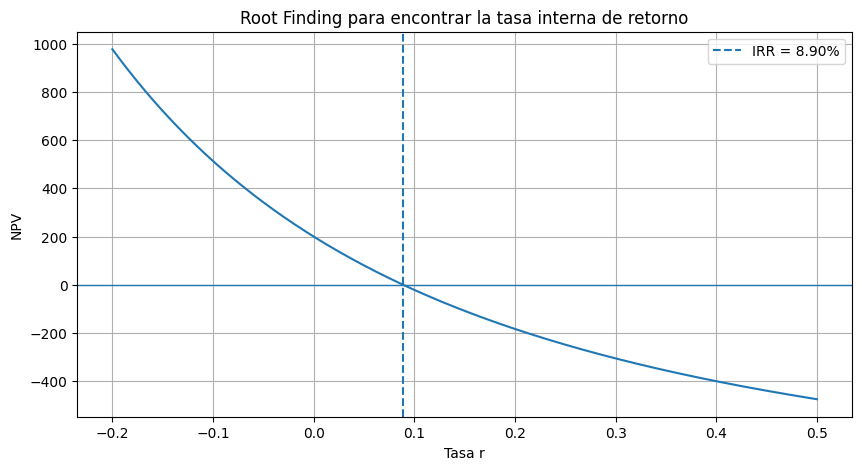

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

cash_flows = [
    -1000,
    300,
    400,
    500
]

def npv(r):

    total = 0.0

    for t, cash in enumerate(cash_flows):
        total += cash / (1 + r)**t

    return total


r_values = np.linspace(
    -0.2,
    0.5,
    1000
)

values = np.array([
    npv(r)
    for r in r_values
])

root = brentq(
    npv,
    -0.2,
    0.5
)

print(
    f"Tasa aproximada = {root:.6f}"
)

print(
    f"Porcentaje = {100*root:.2f}%"
)


plt.figure(figsize=(10, 5))

plt.plot(
    r_values,
    values
)

plt.axhline(0, linewidth=1)

plt.axvline(
    root,
    linestyle="--",
    label=f"IRR = {100*root:.2f}%"
)

plt.xlabel("Tasa r")
plt.ylabel("NPV")
plt.title("Root Finding para encontrar la tasa interna de retorno")

plt.legend()
plt.grid()

plt.show()

Aquí una raíz tiene una interpretación física/económica concreta.

# 31. Ejemplo científico difícil: profundidad de un líquido

Imagina un tanque esférico de radio $(R)$.

El volumen ocupado hasta una altura $(h)$ es:

$V(h)
=$
$\frac{\pi h^2(3R-h)}{3}$


Supongamos:

$R=2\,m$

y queremos almacenar:


$V_{\mathrm{objetivo}}=10\,m^3$

Tenemos que resolver:

$V(h)=10$

Equivalentemente:

$f(h)
=$
$\frac{\pi h^2(6-h)}{3}
-10
=$
$0$


con:

$0\le h\le4$

# 32. Resolverlo con SciPy

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import root_scalar

R = 2.0
V_target = 10.0

def volume(h):

    return (
        np.pi
        * h**2
        * (3*R - h)
        / 3
    )

def f_tank(h):

    return (
        volume(h)
        - V_target
    )


solution = root_scalar(
    f_tank,
    bracket=[0, 2*R],
    method="bisect"
)

h_root = solution.root

print(
    "Altura necesaria =",
    h_root,
    "m"
)

Altura necesaria = 1.4484600107080041 m


Visualizamos:

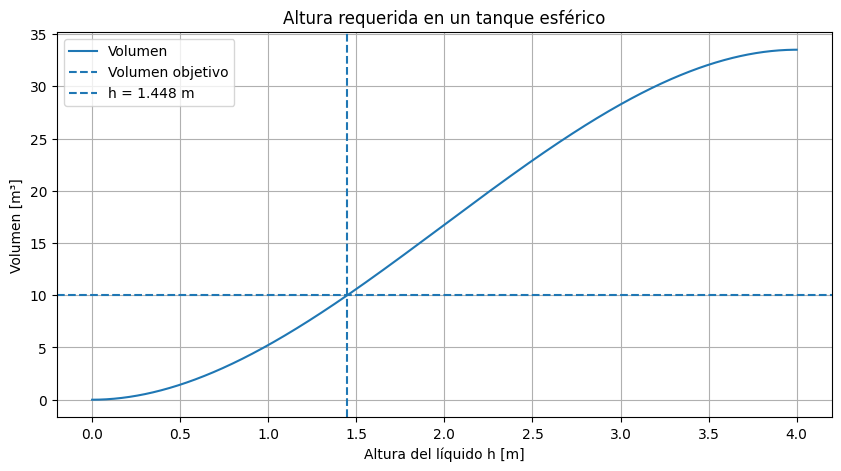

In [15]:
h = np.linspace(
    0,
    2*R,
    1000
)

plt.figure(figsize=(10, 5))

plt.plot(
    h,
    volume(h),
    label="Volumen"
)

plt.axhline(
    V_target,
    linestyle="--",
    label="Volumen objetivo"
)

plt.axvline(
    h_root,
    linestyle="--",
    label=f"h = {h_root:.3f} m"
)

plt.xlabel("Altura del líquido h [m]")
plt.ylabel("Volumen [m³]")

plt.title(
    "Altura requerida en un tanque esférico"
)

plt.legend()
plt.grid()

plt.show()

Este es un caso muy típico de ingeniería:

$\boxed{
\text{modelo físico}
\rightarrow
\text{ecuación no lineal}
\rightarrow
\text{root finding}
}$


# 33. Root Finding dentro de ODEs

Ahora una conexión muy importante para SciML.

Supongamos:

$\frac{dy}{dt}=-ky$

La solución:

$y(t)=y_0e^{-kt}$

Queremos encontrar el instante donde:

$y(t)=0.1$

Definimos:

$g(t)=y(t)-0.1$

Entonces buscamos:

$\boxed{g(t)=0.}$

Eso es root finding.

En simuladores ODE se denomina frecuentemente **event detection**.

# 34. Ejemplo con `solve_ivp`

Tiempo del evento = 1.5350567488324385


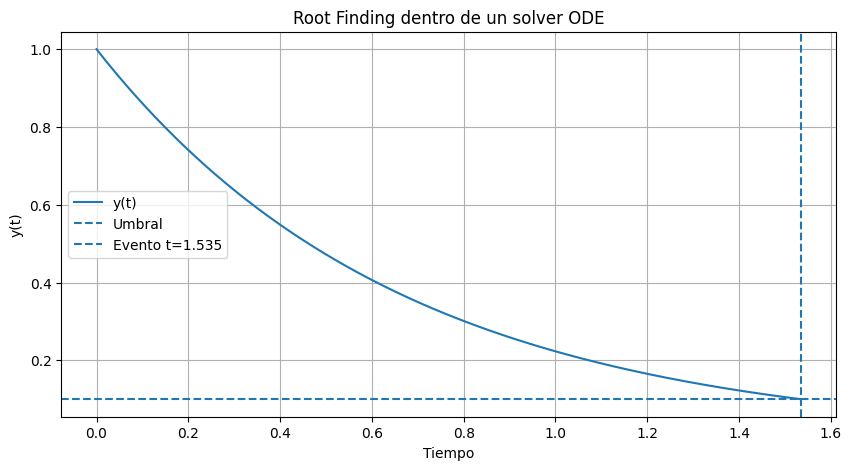

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

k = 1.5

def ode(t, y):
    return [-k * y[0]]

def event(t, y):
    return y[0] - 0.1

event.terminal = True
event.direction = -1


solution = solve_ivp(
    ode,
    [0, 10],
    [1.0],
    events=event,
    dense_output=True,
    max_step=0.1
)

event_time = solution.t_events[0][0]

print(
    "Tiempo del evento =",
    event_time
)

t = np.linspace(
    0,
    event_time,
    500
)

y = solution.sol(t)[0]

plt.figure(figsize=(10, 5))

plt.plot(
    t,
    y,
    label="y(t)"
)

plt.axhline(
    0.1,
    linestyle="--",
    label="Umbral"
)

plt.axvline(
    event_time,
    linestyle="--",
    label=f"Evento t={event_time:.3f}"
)

plt.xlabel("Tiempo")
plt.ylabel("y(t)")

plt.title(
    "Root Finding dentro de un solver ODE"
)

plt.legend()
plt.grid()

plt.show()

Internamente, detectar con precisión cuándo:

$y(t)-0.1=0$

es esencialmente un problema de búsqueda de raíces.

# 35. Una conexión todavía más importante: métodos implícitos

Supongamos la ODE:

$y'=f(t,y)$

Euler explícito:

$y_{n+1}
=$
$y_n
+$
$h f(t_n,y_n)$

Aquí podemos calcular directamente $(y_{n+1})$.

Pero Euler implícito es:

$y_{n+1}
=$
$y_n
+$
$h f(t_{n+1}$ $,y_{n+1})$

$¡(y_{n+1})$ aparece en ambos lados!

Definimos:

$F(z)
=$
$z
$-
$y_n
-$
$hf(t_{n+1},z)$

Entonces necesitamos resolver:

$
\boxed{
F(z)=0.
}$

¿Con qué?

Por ejemplo:

$\boxed{\text{Newton-Raphson}}$

Por eso root finding aparece **dentro de los solvers de ODE/PDE**.

# 36. Ejemplo no lineal implícito

Supongamos:

$y'=-y^3$

Euler implícito:

$y_{n+1}
=$
$y_n
-$
$h y_{n+1}^3$

Movemos todo:

$F(y_{n+1})
=$
$y_{n+1}
+$
$h y_{n+1}^3
-$
$y_n
=$
$0$


Su derivada:

$F'(z)
=$
$1+3hz^2$

Para cada paso temporal tenemos que ejecutar Newton.

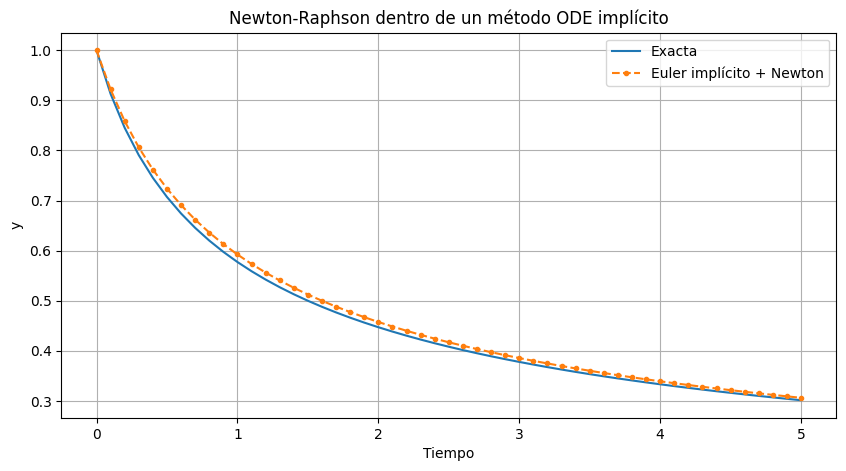

In [17]:
import numpy as np
import matplotlib.pyplot as plt

h = 0.1
T = 5.0

N = int(T / h)

t = np.linspace(
    0,
    T,
    N + 1
)

y = np.zeros(N + 1)

y[0] = 1.0


for n in range(N):

    y_old = y[n]

    # Guess inicial
    z = y_old

    for _ in range(20):

        F = (
            z
            + h*z**3
            - y_old
        )

        dF = (
            1
            + 3*h*z**2
        )

        z_new = (
            z
            - F/dF
        )

        if abs(z_new - z) < 1e-12:
            break

        z = z_new

    y[n + 1] = z_new


# Solución analítica
y_exact = (
    1
    /
    np.sqrt(1 + 2*t)
)


plt.figure(figsize=(10, 5))

plt.plot(
    t,
    y_exact,
    label="Exacta"
)

plt.plot(
    t,
    y,
    "o--",
    markersize=3,
    label="Euler implícito + Newton"
)

plt.xlabel("Tiempo")
plt.ylabel("y")

plt.title(
    "Newton-Raphson dentro de un método ODE implícito"
)

plt.legend()
plt.grid()

plt.show()

Este ejemplo ya está directamente conectado con cálculo científico serio.

# 37. Newton en múltiples dimensiones

En SciML raramente todo será una sola variable.

Podemos tener:

$F(x)=0$

con:

$F:\mathbb R^n\rightarrow\mathbb R^n$

Por ejemplo:

$F(x,y)
=$
$\begin{bmatrix}
x^2+y^2-1\\
x-y
\end{bmatrix}
=$
$0.$

Necesitamos el Jacobiano:

$J_F=
\begin{bmatrix}
\frac{\partial F_1}{\partial x}
&
\frac{\partial F_1}{\partial y}
\\
\frac{\partial F_2}{\partial x}
&
\frac{\partial F_2}{\partial y}
\end{bmatrix}$

Aquí:

$J_F=
\begin{bmatrix}
2x&2y\\
1&-1
\end{bmatrix}$

# 38. Newton multidimensional

En una dimensión:

$x_{n+1}
=$
$x_n
-$
$\frac{f(x_n)}
{f'(x_n)}$

En múltiples dimensiones no hacemos literalmente:

$J^{-1}F$

computando la inversa.

Resolvemos:

$\boxed{
J(x_n)\Delta x=-F(x_n)
}$

y después:

$\boxed{
x_{n+1}=x_n+\Delta x.
}$

Esto conecta directamente root finding con **álgebra lineal**.

# 39. Implementación multidimensional

In [18]:
import numpy as np

def F(z):

    x, y = z

    return np.array([
        x**2 + y**2 - 1,
        x - y
    ])


def J(z):

    x, y = z

    return np.array([
        [2*x, 2*y],
        [1,   -1]
    ])


z = np.array([
    0.8,
    0.6
])

for iteration in range(20):

    delta = np.linalg.solve(
        J(z),
        -F(z)
    )

    z = z + delta

    if np.linalg.norm(delta) < 1e-12:
        break


print("Solución =", z)
print("Residual =", F(z))

Solución = [0.70710678 0.70710678]
Residual = [-2.22044605e-16  0.00000000e+00]


La solución positiva es:

$x=y=\frac1{\sqrt2}$

Aproximadamente:

$x=y\approx0.70710678$

# 40. Visualización del sistema no lineal

Tenemos:

$x^2+y^2=1$

que es un círculo.

Y:

$x=y$

que es una recta.

Sus intersecciones son las raíces.

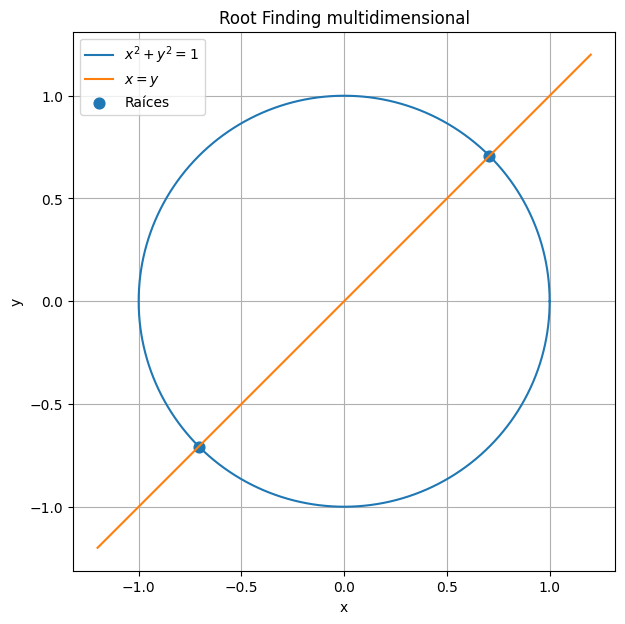

In [19]:
import numpy as np
import matplotlib.pyplot as plt

theta = np.linspace(
    0,
    2*np.pi,
    1000
)

circle_x = np.cos(theta)
circle_y = np.sin(theta)

line_x = np.linspace(
    -1.2,
    1.2,
    500
)

line_y = line_x

plt.figure(figsize=(7, 7))

plt.plot(
    circle_x,
    circle_y,
    label=r"$x^2+y^2=1$"
)

plt.plot(
    line_x,
    line_y,
    label=r"$x=y$"
)

root = 1 / np.sqrt(2)

plt.scatter(
    [root, -root],
    [root, -root],
    s=60,
    label="Raíces"
)

plt.xlabel("x")
plt.ylabel("y")
plt.title("Root Finding multidimensional")

plt.axis("equal")
plt.legend()
plt.grid()

plt.show()

Ahora root finding ya no significa necesariamente "dónde una curva cruza el eje $(x)$".

Significa encontrar:

$\boxed{F(\mathbf x)=\mathbf0}$

# 41. Root finding y optimización

Hay otra conexión importantísima.

Para minimizar:

$L(\theta)$,

un candidato a mínimo satisface:

$\boxed{
\nabla_\theta L(\theta)=0.
}$

Esto es un problema de root finding:

$F(\theta)
=$
$\nabla L(\theta)
=$
$0$

Newton para optimización aparece entonces como:

$\theta_{n+1}
=$
$\theta_n
-$
$H^{-1}
\nabla L$

donde:

$H=\nabla^2L$

es el Hessiano.

Más correctamente, numéricamente resolvemos:

$\boxed{
H\Delta\theta=-\nabla L
}$

y:

$\theta_{n+1}
=$
$\theta_n+\Delta\theta$

Esto es la versión multidimensional de Newton-Raphson aplicada al gradiente.

Por eso existe una línea directa:

$\boxed{
\text{Root Finding}
\rightarrow
\text{Newton}
\rightarrow
\text{Jacobianos/Hessianos}
\rightarrow
\text{Optimización}
\rightarrow
\text{ML/SciML}
}$

# 42. Ejemplo difícil: equilibrio físico no lineal

Imagina un resorte no lineal cuya fuerza es:

$F_s(x)=kx+\beta x^3$

Aplicamos una fuerza externa:

$F_{\mathrm{ext}}$

En equilibrio:

$F_s(x)=F_{\mathrm{ext}}$

Por tanto:

$\boxed{
kx+\beta x^3-F_{\mathrm{ext}}=0.
}$

Supongamos:

$
k=10,
\qquad
\beta=50,
\qquad
F_{\mathrm{ext}}=20$

Queremos encontrar la deformación $(x)$

Deformación de equilibrio = 0.646835 m


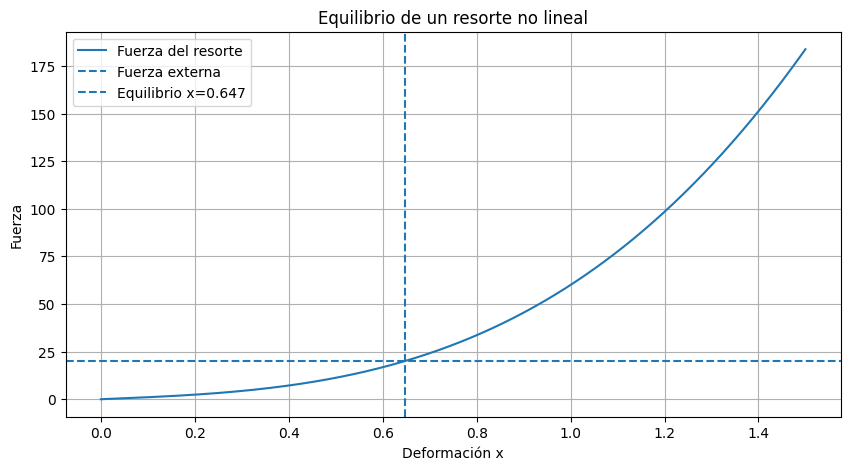

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import root_scalar

k = 10.0
beta = 50.0
F_external = 20.0

def residual(x):

    return (
        k*x
        + beta*x**3
        - F_external
    )


solution = root_scalar(
    residual,
    bracket=[0, 2],
    method="brentq"
)

root = solution.root

print(
    f"Deformación de equilibrio = {root:.6f} m"
)


x = np.linspace(
    0,
    1.5,
    1000
)

spring_force = (
    k*x
    + beta*x**3
)

plt.figure(figsize=(10, 5))

plt.plot(
    x,
    spring_force,
    label="Fuerza del resorte"
)

plt.axhline(
    F_external,
    linestyle="--",
    label="Fuerza externa"
)

plt.axvline(
    root,
    linestyle="--",
    label=f"Equilibrio x={root:.3f}"
)

plt.xlabel("Deformación x")
plt.ylabel("Fuerza")

plt.title(
    "Equilibrio de un resorte no lineal"
)

plt.legend()
plt.grid()

plt.show()

La raíz representa literalmente el **estado de equilibrio del sistema físico**.

# 43. Comparación profunda de los métodos

Ahora podemos entender mejor sus diferencias:

| Propiedad | Bisección | Newton | Secante |
|---|---:|---:|---:|
| Derivada | No | Sí | No |
| Valores iniciales | $(a,b)$ | $(x_0)$ | $(x_0,x_1)$ |
| Necesita cambio de signo | Sí | No | No |
| Convergencia local típica | lineal | cuadrática | superlineal |
| Orden | $(1)$ | $(2)$ | $(\approx1.618)$ |
| Garantía con buenas hipótesis | Alta | No | No |
| Coste por iteración | Bajo | puede ser alto | bajo |
| Puede divergir | difícil con bracket válido | Sí | Sí |
| Uso en problemas grandes | limitado | muy importante | útil |

# 44. Entonces, ¿cuál usar?

No existe un ganador universal.

Si tienes un intervalo:

$[a,b]$

con:

$f(a)f(b)<0$

y quieres **robustez**, Bisección es excelente.

Si tienes:

- buena estimación inicial;
- derivada disponible;
- función suficientemente suave;

Newton suele ser muchísimo más rápido.

Si la derivada es costosa o desconocida, Secante puede ser una gran alternativa.

En la práctica también existen métodos híbridos.

Uno especialmente importante es **Brent**.

SciPy ofrece:

```python
from scipy.optimize import brentq
```

Combina ideas para obtener buena robustez y velocidad.

# 45. Una práctica numérica importante

En vez de comprobar únicamente:

```python
abs(f(x)) < tolerance
```

a menudo queremos considerar también el cambio en $(x)$:

```python
abs(x_new - x_old) < atol + rtol * abs(x_new)
```

donde:

- `atol`: tolerancia absoluta;
- `rtol`: tolerancia relativa.

Esto conecta directamente con lo que acabas de estudiar sobre:

$\boxed{\text{error absoluto + error relativo}}$


Para problemas científicos con escalas muy diferentes, esto importa bastante.

# 46. Root finding y SciML

Ahora podemos hacer la conexión completa.

Supongamos un modelo físico:

$F(u,\theta)=0$

Aquí:

- $(u)$: estado físico;
- $(\theta)$: parámetros.

Para cada $(\theta)$, quizá necesitamos resolver:

$F(u,\theta)=0$

para encontrar:

$u^*(\theta)$

Después tenemos observaciones:

$u_{\text{obs}}$

Y queremos aprender:

$$
\theta^*
=
\arg\min_{\theta}
\left\|
u^*(\theta)
-
u_{\text{obs}}
\right\|^2
$$

Observa la estructura:

$$\boxed{
\theta
\rightarrow
\text{Root Solver}
\rightarrow
u^*(\theta)
\rightarrow
\text{Loss}
\rightarrow
\text{Optimización}
}$$

En SciML podemos incluso querer diferenciar **a través del solver**.

# 47. Diferenciación implícita

Supongamos:

$$
F(u,\theta)=0.
$$

La solución:

$$
u=u(\theta)
$$

depende de los parámetros.

Derivamos respecto a $(\theta)$:

$$
\frac{\partial F}{\partial u}
\frac{du}{d\theta}
+
\frac{\partial F}{\partial\theta}
=
0$$

Entonces:

$$
\boxed{
\frac{du}{d\theta}
=
-
\left(
\frac{\partial F}{\partial u}
\right)^{-1}
\frac{\partial F}{\partial\theta}
}$$

En implementación numérica normalmente **no calculamos esa inversa explícitamente**; resolvemos un sistema lineal.

Esta fórmula es extremadamente importante.

Conecta:

$$
\text{Root Finding}
$$

con:

$$
\text{Implicit Differentiation}
$$

con:

$$
\text{Differentiable Programming}
$$

con:

$$
\boxed{\text{Scientific Machine Learning}}.
$$


# 48. El mapa mental que quiero que conserves

Todo comienza con:

$$
\boxed{f(x)=0}
$$

### Bisección

Busca una raíz encerrándola:

$$f(a)f(b)<0$$

y:

$$
[a,b]
\rightarrow
\frac12[a,b]
\rightarrow
\frac14[a,b]
\rightarrow\cdots
$$

Es:

$$
\boxed{\text{lenta pero robusta}.}
$$

### Newton

Linealiza localmente:

$$f(x)
\approx
f(x_n)
+
f'(x_n)(x-x_n)
$$

y obtiene:

$$
\boxed{
x_{n+1}
=
x_n
-
\frac{f(x_n)}{f'(x_n)}
}
$$

Es:

$$
\boxed{\text{muy rápida cerca de una raíz simple}.}
$$

### Secante

Aproxima:

$$f'(x)$$

con dos evaluaciones:


$$\frac{f(x_n)-f(x_{n-1})}
{x_n-x_{n-1}}$$

y obtiene:

$$
\boxed{
x_{n+1}
=
x_n
-
f(x_n)
\frac{x_n-x_{n-1}}
{f(x_n)-f(x_{n-1})}
}
$$

Es el compromiso:

$$\boxed{\text{velocidad sin derivada}.}$$

| **Inicio**         | **atrás 1**                          | **Siguiente 3**                                    |
| ------------------ | ------------------------------------ | -------------------------------------------------- |
| [🏠](../README.md) | [⏪](./6_1_Errores.ipynb) | [⏩](./6_3_Interpolacion.ipynb) |